In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

In [4]:
df = pd.read_csv('/Users/sachinchoudhary/Developer/ML/data/titanic_toy.csv')
df.sample(5)

,Age,Fare,Family,Survived
53,29.0,26.000,1,1
121,NaN,8.050,0,0
98,34.0,NaN,1,1
92,46.0,61.175,1,0
304,NaN,8.050,0,0


In [5]:
X = df.iloc[:,:3]
y = df['Survived']

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=3)

In [11]:
X_train['Age_99'] = X_train['Age'].fillna(99)
X_train['Age_minus1'] = X_train['Age'].fillna(-1)

X_train['Fare_999'] = X_train['Fare'].fillna(999)
X_train['Fare_minus1'] = X_train['Fare'].fillna(-1)

In [12]:
X_train.sample(5)

,Age,Fare,Family,Age_99,Age_minus1,Fare_99,Fare_minus1,Fare_999
249,54.0,26.0000,1,54.0,54.0,26.0000,26.0000,26.0000
767,30.5,7.7500,0,30.5,30.5,7.7500,7.7500,7.7500
503,37.0,9.5875,0,37.0,37.0,9.5875,9.5875,9.5875
676,24.5,8.0500,0,24.5,24.5,8.0500,8.0500,8.0500
277,NaN,0.0000,0,99.0,-1.0,0.0000,0.0000,0.0000


In [13]:
print('Original Age Variable Variance ->', X_train['Age'].var())
print('Age Variance After 99 vala Imputation ->', X_train['Age_99'].var())
print('Age Variance after -1 vala Imputation ->',X_train['Age_minus1'].var())

print('Original Fare Variable Variance ->', X_train['Fare'].var())
print('Fare Variance After 999 vala Imputation ->', X_train['Fare_999'].var())
print('Fare Variance after -1 vala Imputation ->',X_train['Fare_minus1'].var())

Original Age Variable Variance -> 219.41287982680032
Age Variance After 99 vala Imputation -> 937.4535691744102
Age Variance after -1 vala Imputation -> 333.30110153111616
Original Fare Variable Variance -> 2567.9276867284257
Fare Variance After 999 vala Imputation -> 48572.26704667504
Fare Variance after -1 vala Imputation -> 2487.840365627623


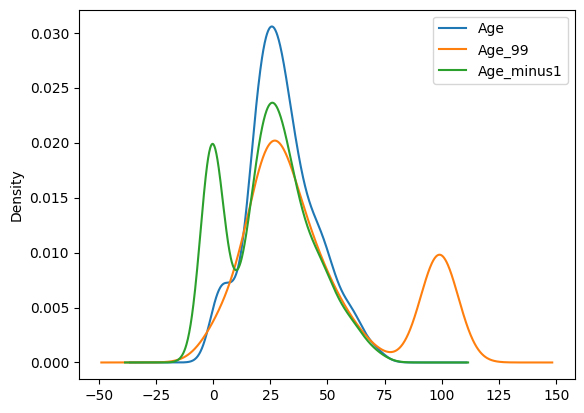

In [14]:
fig = plt.figure()
ax = fig.add_subplot(111)

X_train['Age'].plot(kind='kde',ax = ax)
X_train['Age_99'].plot(kind='kde',ax = ax)
X_train['Age_minus1'].plot(kind='kde',ax = ax)

lines, labels = ax.get_legend_handles_labels()
ax.legend(lines, labels, loc='best')

plt.show()

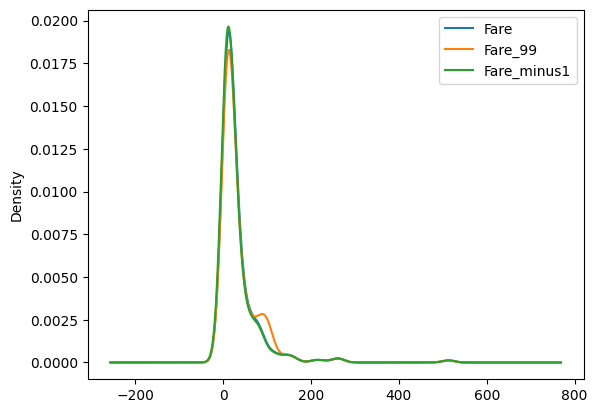

In [15]:
fig = plt.figure()
ax = fig.add_subplot(111)

X_train['Fare'].plot(kind='kde',ax = ax)
X_train['Fare_99'].plot(kind='kde',ax = ax)
X_train['Fare_minus1'].plot(kind='kde',ax = ax)

lines, labels = ax.get_legend_handles_labels()
ax.legend(lines, labels, loc='best')

plt.show()

#### using sklearn

In [16]:
imputer1 = SimpleImputer(strategy='constant', fill_value=99)
imputer2 = SimpleImputer(strategy='constant', fill_value=-1)